# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 1</span>

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Central limit theorem 
If $\{X_k\}_{k \le 1}$ is a sequence of real-valued, square-integrable random variables, independent and identically distributed, let $ \mu=E [X_k]$ and $\sigma^2=Var(X_k)$, the sequence:
\begin{equation}
S_n =\frac{\frac{1}{2} \sum(X_k - \mu)}{\sigma / \sqrt{n}}
\end{equation}
converges in law to a standard normal random variable 

E. Vitali, M. Motta , D.Galli - Theory and simulation of random phenomena 


# How to sample a distribution 
A sampling procedure is an algorithm that allows me to create random numbers that follow a specific probability density. The general workflow of sampling a chosen distribution p(x) follows a structured path:
1. **Generation of Basic Randomness:** The first step is to sample random numbers $y$ that are independent and uniformly distributed on the interval $[0,1)$
2. **Calculate the cumulative distribution:** Once you have your number, you calculate the cumulative distribution of your PDF
   \begin{equation}
   F(x) = \int_{-\infty}^{x} p(x')dx'
   \end{equation}
3. **Invert the function:** If F(x) is known and if it is analytically invertible, you may solve for $x$ to obtain the sampling formula
   \begin{equation}
   x = F^{-1}(y)
   \end{equation}
(y is a random number found in the first passage) 


# Data blocking 
Data blocking is a statistical technique used particularly in Monte Carlo simulations to calculate reliable averages and uncertainties when data are not independent. <br>
How data blocking works :
1. **Division:** The total number of steps M is divided into N large blocks
2. **Block average:** For each block (with fixed size), an average of the quantity regarded must be calculated 
3. **Treat each block as a measure:** You treat each block average $A_i$ as a single, independent measurement, instead of using the original $M$ correlated data points directly.
4. **Progressive average and uncertainty:** At this point everything becomes clear:
    $$ \langle A^2 \rangle \simeq \frac{1}{N} \sum_{i=1}^N A^2_i \quad \quad \langle A\rangle^2 \simeq \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 $$
    and finally the statistical uncertainty with $N$ :
    $$\frac{\sigma}{\sqrt{N-1}} \simeq \sqrt{\frac{1}{N-1} \left[ \frac{1}{N} \sum_{i=1}^N A^2_i - \left( \frac{1}{N} \sum_{i=1}^N A_i \right)^2 \right]} $$
</p>

---
---

## Exercise 01.1

### Results
Hereafter, we consider,  for the solution of this first exercise, a set of $10^5$ throws and  $10^2$ blocks. With these parameters, we compute the mean value and the variance through data blocking.<br>
The following plots show, as a function of the number of blocks, the progressive averages
$$\langle r \rangle - \frac{1}{2} \qquad \text{and} \qquad \langle (r - 1/2)^2 \rangle - \frac{1}{12},$$
together with the corresponding statistical uncertainty $\sigma_N$.

As expected, both quantities fluctuate around zero (expectation values on the red dotted line), and the error bars shrink as the number of blocks increases, consistent with the data blocking.

The third part of the exercise tests whether $r$ is compatible with being drawn from a uniform distribution, using a $\chi^2$ test as described in Assignment 1.03. If the computed $\chi^2$ values are compatible with the expected value $\chi^2 \approx M$, we cannot reject the null hypothesis of uniformity.

The resulting $\chi^2$ values are indeed compatible with $M = 100$, in good agreement with the uniform distribution hypothesis.

---

**Exercise**
1. $\langle r \rangle = \int_0^1 r dr = 1/2$. <font color="red">Make a picture of the estimation of $\langle r \rangle$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle r \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

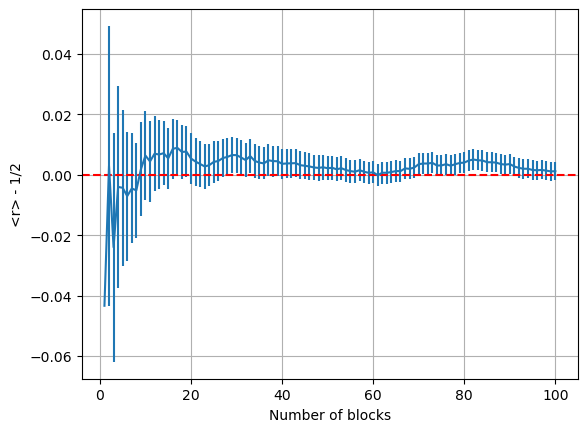

In [9]:
data = np.loadtxt("ex1_1/data.txt")

x = data[:,0]
mean = data[:,1]
err = data[:,2]
plt.errorbar(x, mean-0.5, yerr=err)
plt.axhline(y=0, color='red', linestyle='--', label='Valore teorico')

plt.xlabel("Number of blocks")
plt.ylabel("<r> - 1/2")
plt.grid(True)

plt.show()

2. $\sigma^2 = \int_0^1 (r-1/2)^2 dr = 1/12$. <font color="red">Make a picture of the estimation of $\sigma^2$ and its uncertainty (which corresponds to Standard Deviation of the mean for the estimation of $\langle (r-1/2)^2 \rangle$) with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties).

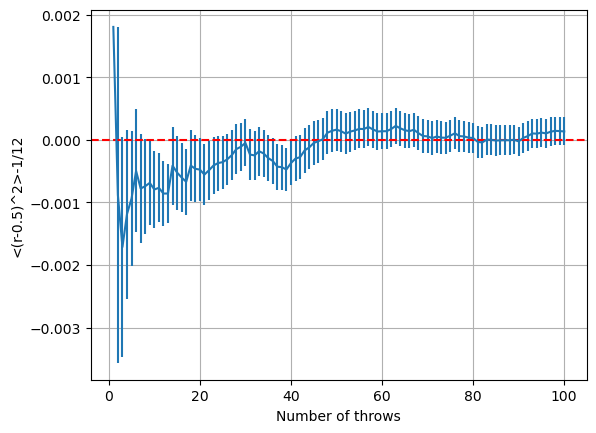

In [11]:
data = np.loadtxt("ex1_1/data1.txt")

x = data[:,0]
mean = data[:,1]
err = data[:,2]

plt.errorbar(x, mean-(1.0/12), yerr=err)
plt.axhline(y=0, color='red', linestyle='--', label='Valore teorico')

plt.xlabel("Number of throws")
plt.ylabel("<(r-0.5)^2>-1/12")
plt.grid(True)

plt.show()

3. Divide $[0,1]$ into $M$ identical sub-intervals and implement the $\chi^2$ test. Obviously, the number of expected events observed in each sub-interval after $n$ *throws*, according to a uniform distribution, is $np = n\times 1/M= n/M$. Fix $M=10^2$ and use for $n$ the first $10^4$ pseudo-random numbers, then the successive $10^4$ pseudo-random numbers, and so on ... 100 times. <font color="red">Plot $\chi^2_j$ for $j=1, ..., 100$</font>. In this case the chi-square statistic is:
$$\chi^2 = \sum_{i=1}^M \frac{\left( n_i - n/M \right)^2}{n/M}$$
We should expect on average that $(n_i - n/M)^2 \simeq n/M$ and thus $\chi^2 \simeq 100$, i.e. the number of sub-intervals.
A larger value of $\chi^2$ indicates that the hypothesis ($n_i$ are drawn from a uniform distribution) is rather unlikely ... <font color="red">but before judging</font>, you could compare the histogram of the values obtained for $\chi^2_j$ with the true probability distribution (see: <a href="https://en.wikipedia.org/wiki/Chi-squared_distribution">this Wikipedia link</a>).


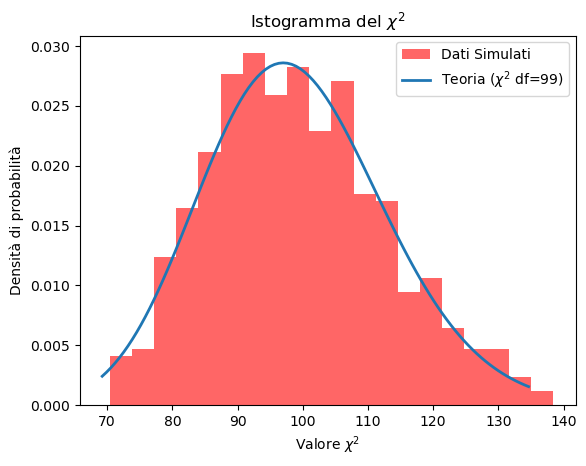

In [32]:
from scipy.stats import chi2  # Import fondamentale per definire chi2
# Carica i dati dal file prodotto dal tuo C++
data = np.loadtxt("ex1_1/data2.txt")

# Crea l'istogramma dei tuoi risultati
plt.hist(data, bins=20, density=True, alpha=0.6, color='r', label='Dati Simulati')

# Calcola la densità di probabilità teorica del chi-quadro
df = 99
x = np.linspace(chi2.ppf(0.01, df), chi2.ppf(0.99, df), 100)
plt.plot(x, chi2.pdf(x, df), lw=2, label=rf'Teoria ($\chi^2$ df={df})')

plt.title(r"Istogramma del $\chi^2$")
plt.xlabel(r"Valore $\chi^2$")
plt.ylabel(r"Densità di probabilità")
plt.legend()
plt.show()

## Exercise 01.2

### Results

In this section we verify the Central Limit Theorem (CLT) for several distributions, and also study one distribution that violates the CLT hypotheses (infinite variance). The distributions considered are: uniform, exponential, Rayleigh, and Lorentzian. The first three satisfy the CLT hypotheses, while the Lorentzian does not, due to its diverging variance.

For each distribution, we first sample from its cumulative distribution function (see the theory section above), and then compute the sample mean
$$S_N = \frac{1}{N}\sum_{i=1}^{N} x_i$$
over $10^4$ realizations, for increasing values of $N$ (number of throws being averaged). The resulting histograms show the distribution of $S_N$ for each value of $N$.

As expected from the CLT, for the uniform, exponential, and Rayleigh distributions the histograms of $S_N$ progressively approach a Gaussian shape as $N$ increases. In contrast, for the Lorentzian distribution the histograms of $S_N$ do not converge to a Gaussian, regardless of $N$ , a direct consequence of its infinite variance, which violates one of the CLT's key hypotheses.

---

**Exercise**
1. <font color="red">Add two probability distributions</font> by using the **method of the inversion of the cumulative distribution** to sample from a **generic** <font color="red">exponential distribution</font>, $p(x) = \lambda \exp(-\lambda x)$, $x\in [0;+\infty]$ (see <a href="https://en.wikipedia.org/wiki/Exponential_distribution">this Wikipedia link</a>), and a **generic** <font color="red">Cauchy-Lorentz distribution</font> $p(x)=\frac{1}{\pi}\frac{\Gamma}{(x-\mu)^2+\Gamma^2}$, $x\in [-\infty;+\infty]$ (see <a href="https://en.wikipedia.org/wiki/Cauchy_distribution">this Wikipedia link</a>).
2. <font color="red">Make 3 pictures</font> with the histograms obtained filling them with $10^4$ realizations of $S_N = \frac{1}{N}\sum_{i=1}^N x_i$ (for $N=1, 2, 10, 100$), being $x_i$ a random variable sampled throwing a *standard* dice (fig.1), an *exponential* dice (fig.2, use $\lambda=1$) and a *Lorentzian* dice (fig.3, use $\mu=0$ and $\Gamma=1$).



### Uniform distribution 
\begin{equation}
x =  6y +1
\end{equation}

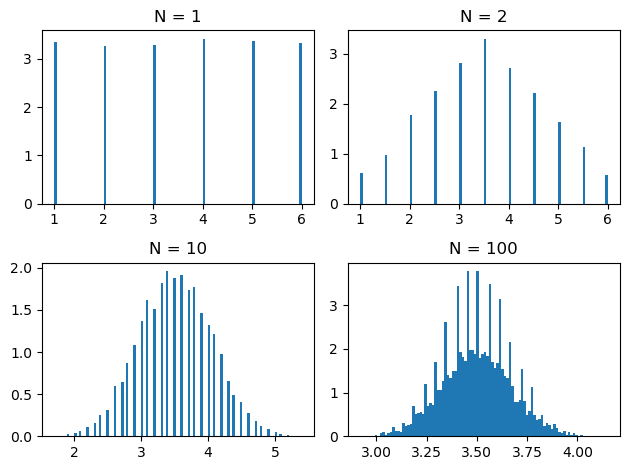

In [35]:
data = np.loadtxt("ex1_2/S_unif.txt")

N = [1,2,10,100]

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.hist(data[i], bins=100, density=True)
    plt.title("N = "+str(N[i]))
plt.tight_layout()
plt.show()

### Exponential distribution  
\begin{equation}
x =  -\log{(1-y)}
\end{equation}

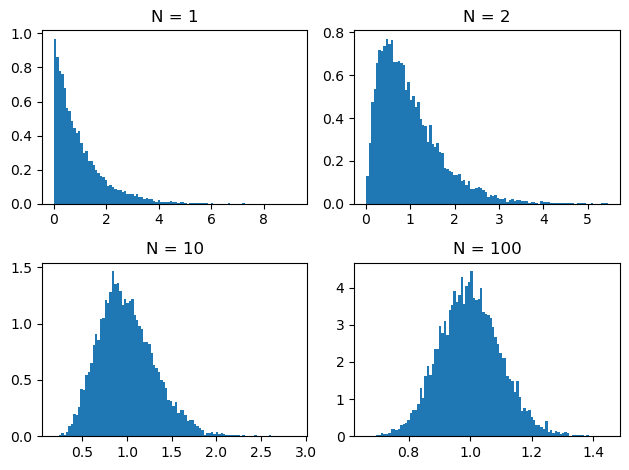

In [33]:

data = np.loadtxt("ex1_2/S_exp.txt")

N = [1,2,10,100]

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.hist(data[i], bins=100, density=True)
    plt.title("N = "+str(N[i]))
    
plt.tight_layout()
plt.show()


### Rayleigh distribution 
\begin{equation}
x =  \sqrt{-2 \cdot \ln{(1-y)}}
\end{equation}

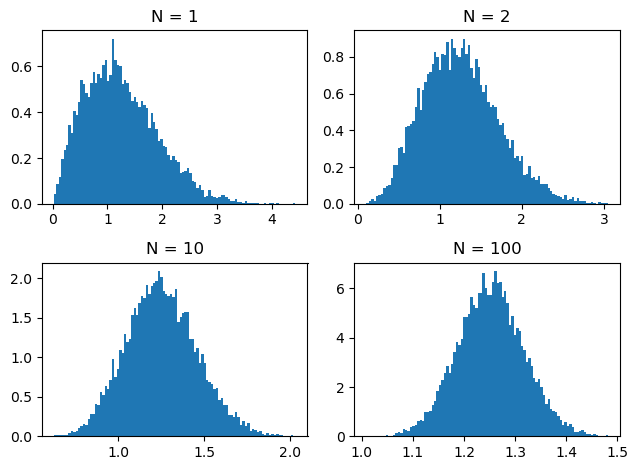

In [72]:
data = np.loadtxt("ex1_2/S_Ray.txt")

N = [1,2,10,100]

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.hist(data[i], bins=100, density=True)
    plt.title("N = "+str(N[i]))
    
plt.tight_layout()
plt.show()

### Lorentzian distribution 
\begin{equation}
x =  \tan{(\pi \cdot (y-0.5))}
\end{equation}

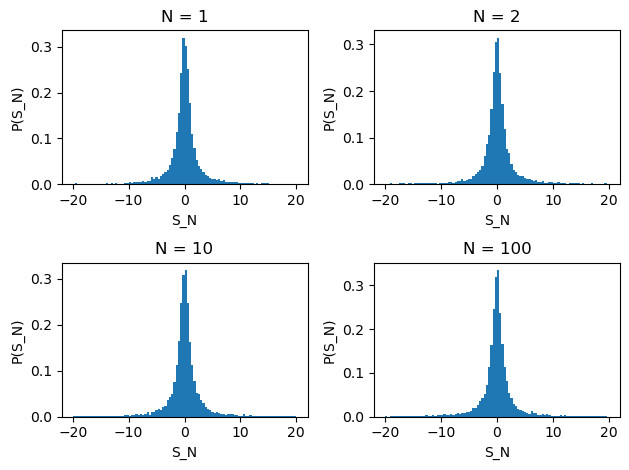

In [49]:
data = np.loadtxt("ex1_2/S_lor.txt")

N = [1,2,10,100]

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.hist(data[i], bins=100, range=(-20, 20), density=True)
    plt.title("N = " + str(N[i]))
    plt.xlabel("S_N")
    plt.ylabel("P(S_N)")

plt.tight_layout()
plt.show()


## Exercise 01.3

## Results

To solve this exercise, I simulate Buffon's experiment in a $10\times10$ unit square, divided into $10$ horizontal strips of equal width $d$. The idea is to sample the position of the first end of a needle from two uniform distributions, $y_0 \in (0,10)$, and then to sample a random angle $\theta \in (0,2\pi)$ defining the needle's orientation. If the needle (of length $L$) crosses one of the strip boundaries, the hit counter $N_{hit}$ is incremented; otherwise, a new needle is thrown, and the process is repeated. The graph below represents the $\pi$ estimator as a function of the number of blocks.<br>
To avoid the tautology of using $\pi$ to sample the angle, one can use the accept-reject algorithm, sampling a point inside a unit circle in order to obtain $\sin(\theta)$ directly, without ever generating $\theta$ itself.

---

**Exercise**
- **Simulate** the Buffon’s experiment (see LSN_Lecture_00, supplementary material):  A needle of length $L$ is thrown at random onto a horizontal plane ruled with straight lines a distance $d$ (must be $d > L$, but do not use $d\gg L$ otherwise $P\ll 1$) apart. The probability $P$ that the needle will intersect one of these lines is: $P = 2L/\pi d$. This could be used to evaluate $\pi$ from throws of the needle: if the needle is thrown down $N_{thr}$ times and is observed to land on a line $N_{hit}$ of those times, we can make an estimate of $\pi$ from
$$\pi = \frac{2L}{Pd} = \lim_{N_{thr} \to \infty}\frac{2LN_{thr}}{N_{hit}d}$$
<font color="red">Make a picture of the estimation of $\pi$ and its uncertainty (Standard Deviation of the mean) with a large number of *throws* $M$ as a function of the number of blocks, $N$</font> (see below: Computing statistical uncertainties). If possible, do not use $\pi$ to evaluate $\pi$.

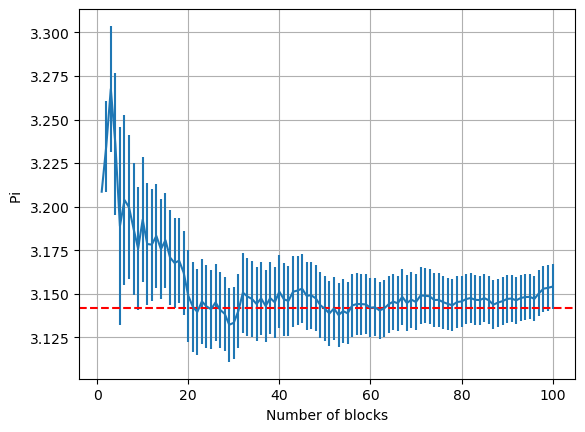

In [108]:
data = np.loadtxt("ex1_3/pi_data.txt")

x = data[:,0]
mean = data[:,1]
err = data[:,2]

plt.errorbar(x, mean, yerr=err)
plt.axhline(y=np.pi, color='red', linestyle='--', label='Valore teorico')

plt.xlabel("Number of blocks")
plt.ylabel("Pi ")
plt.grid(True)

plt.show()